In [199]:
import tarfile
import gzip
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy
import warnings
from numpy.polynomial import Polynomial
from scipy.signal import savgol_filter, find_peaks
from scipy.optimize import curve_fit
from scipy.optimize import minimize_scalar
import requests
from pathlib import Path
from IPython.display import display

In [200]:
descargas = {
    "J_PASP_107_1042.tar.gz": "https://cdsarc.cds.unistra.fr/viz-bin/nph-Cat/tar.gz?J/PASP/107/1042",
    "J_ApJS_94_221.tar.gz":   "https://cdsarc.cds.unistra.fr/viz-bin/nph-Cat/tar.gz?J/ApJS/94/221",
}

for nombre, url in descargas.items():
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    with open(nombre, "wb") as f:
        f.write(r.content)
    print(f"{nombre}: listo ({len(r.content)/1e6:.1f} MB)")

J_PASP_107_1042.tar.gz: listo (9.0 MB)
J_ApJS_94_221.tar.gz: listo (0.5 MB)


In [201]:
tar = tarfile.open("J_PASP_107_1042.tar.gz","r:*")
tar.extractall("espectros", filter='data')

tar2 = tarfile.open("J_ApJS_94_221.tar.gz","r:*")
tar2.extractall("lineas", filter='data')

In [202]:
spectral_files = [
    name for name in tar.getnames()
    if "ab" in name and name.endswith(".gz")
]

print(len(spectral_files))

310


In [214]:
all_spectra = []

for file_name in spectral_files:

    file = tar.extractfile(file_name)

    with gzip.open(file, 'rt') as f:
        df = pd.read_csv(
            f,
            sep=r'\s+',
            header=None
        )


    temp = pd.DataFrame({
        "wavenumber": df[0],
        "intensity": df[1]
    })

    all_spectra.append(temp)

Sabemos que $$\lambda =
\frac{1}{\tilde{\nu}}$$

Y $$1 cm = 10^{8} Å$$

In [215]:
spectra = pd.concat(all_spectra)

spectra = spectra.drop_duplicates(
    subset="wavenumber"
)


spectra.head()

spectra["lambda"] = 1e8 / spectra["wavenumber"]

spectra = spectra.sort_values("lambda")

print(spectra)

      wavenumber  intensity        lambda
1420    10953.40    0.57325   9129.585334
1419    10953.36    0.56870   9129.618674
1418    10953.32    0.58553   9129.652014
1417    10953.28    0.62694   9129.685355
1416    10953.24    0.65616   9129.718695
...          ...        ...           ...
4        1866.04    0.00000  53589.419305
3        1866.03    0.00000  53589.706489
2        1866.02    0.00000  53589.993676
1        1866.01    0.00000  53590.280867
0        1866.00    0.00000  53590.568060

[347034 rows x 3 columns]


In [227]:
spectra["wavenumber"] = pd.to_numeric(spectra["wavenumber"], errors='coerce')
spectra["intensity"] = pd.to_numeric(spectra["intensity"], errors='coerce')
spectra = spectra.dropna(subset=["wavenumber", "intensity"])

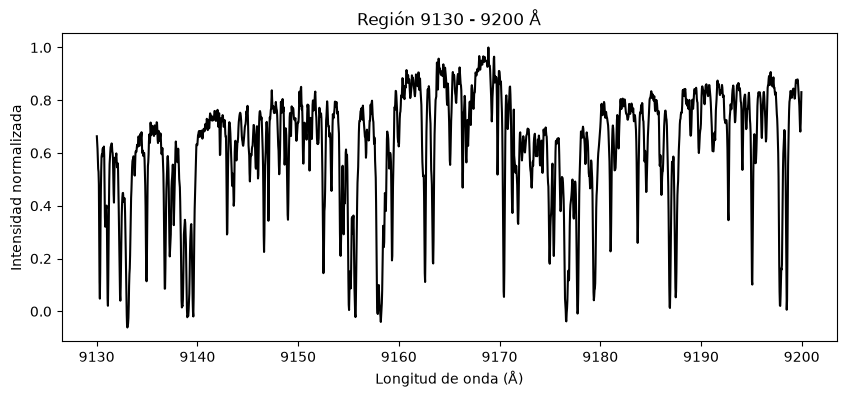

In [228]:
lambdai = 9130
lambdaf = 9200

region = spectra[
    (spectra["lambda"] > lambdai) &
    (spectra["lambda"] < lambdaf)
]

plt.figure(figsize=(10,4))

plt.plot(
    region["lambda"],
    region["intensity"],
    color="black"
)

plt.xlabel("Longitud de onda (Å)")
plt.ylabel("Intensidad normalizada")

plt.title(f"Región {lambdai} - {lambdaf} Å")

plt.show()

In [218]:
file = tar2.extractfile("./table2.gz")
with gzip.open(file,'rt') as f:

    lines = pd.read_fwf(
        f,
        colspecs=[
            (0,4),      # Num
            (5,15),     # Term1
            (15,16),    # -
            (16,26),    # Term2
            (27,28),    # J1
            (28,29),    # -
            (29,30),    # J2
            (30,36),    # I
            (37,47),    # Lvac
            (48,58),    # Lair
            (59,65),    # Lo-R
            (65,75),    # Sigma
            (76,77),    # q_Sigma
            (79,83),    # So-R
            (84,89),    # El
            (90,95),    # Eu
            (96,105),   # Elc
            (106,115),  # Euc
            (116,122),  # loggf
            (123,124),  # source
            (126,131)   # Blend
        ]
    )

lines.columns = [
"Num","Term1","dash1","Term2","J1","dash2","J2",
"I","Lvac","Lair","LoR","Sigma","qSigma","SoR",
"El","Eu","Elc","Euc","loggf","source","Blend"
]

 En el catálogo dice que las unidades de Lvac están en 0.1nm = 1Å, así que no hay que convertir nada. Usamos Lvacío porque con los datos de Hinkle se usó un interferómetro de transformada de Fourier.

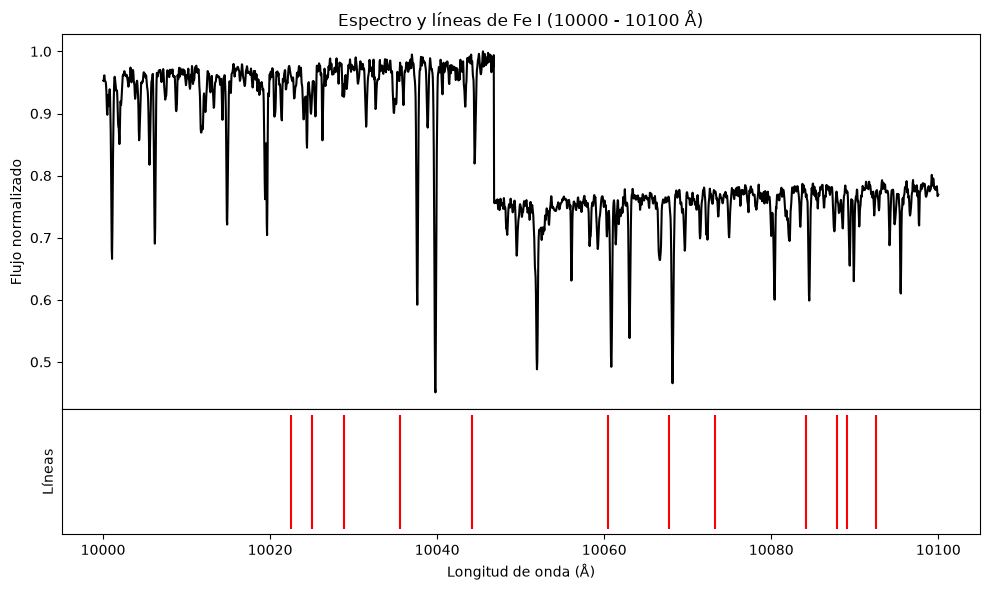

In [219]:
lines["lambda"] = lines["Lvac"]

fe_lines = lines[
    lines["qSigma"] == "A"
]

lambda_min = 10000
lambda_max = 10100

copy_fe_lines = fe_lines.copy()
copy_fe_lines = copy_fe_lines[
    (copy_fe_lines["lambda"] > lambda_min) &
    (copy_fe_lines["lambda"] < lambda_max)
]

espectro = spectra.copy()
espectro = espectro[
    (espectro["lambda"] > lambda_min) &
    (espectro["lambda"] < lambda_max)
]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})


ax1.plot(espectro["lambda"], espectro["intensity"], color="black")
ax1.set_ylabel("Flujo normalizado")
ax1.set_title(f"Espectro y líneas de Fe I ({lambda_min} - {lambda_max} Å)")


ax2.vlines(
    copy_fe_lines["lambda"],
    ymin=0,
    ymax=1,
    color="red"
)
ax2.set_ylabel("Líneas")
ax2.set_xlabel("Longitud de onda (Å)")
ax2.set_yticks([])


plt.tight_layout()
plt.subplots_adjust(hspace=0)
plt.show()

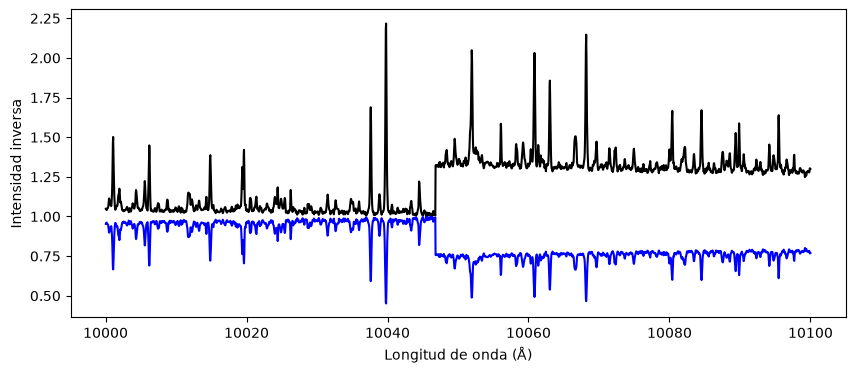

In [220]:
z_identificacion = 0.000045
fe_lines = fe_lines.copy()
fe_lines["lambda"] = pd.to_numeric(
    fe_lines["Lvac"],
    errors="coerce"
)

fe_lines = fe_lines.dropna(
    subset=["lambda"]
).copy()

fe_lines["lambda_identificacion"] = (
    fe_lines["lambda"] * (1 + z_identificacion)
)

fe_lines = fe_lines.sort_values(
    "lambda_identificacion"
).reset_index(drop=True)

intensidad_inversa = 1 / espectro["intensity"]
plt.figure(figsize=(10,4))
plt.plot(
    espectro["lambda"],
    intensidad_inversa,
    color="black"
)
plt.plot(
    espectro["lambda"],
    espectro["intensity"],
    color="blue",
)
plt.xlabel("Longitud de onda (Å)")
plt.ylabel("Intensidad inversa")
plt.show()

In [243]:
flujo_inverso = 1 / spectra["intensity"]
minimos = scipy.signal.find_peaks(flujo_inverso, distance=1, prominence=0.2)
lambdas_minimos = spectra["lambda"].iloc[minimos[0]].values
intensidades_minimos = spectra["intensity"].iloc[minimos[0]].values
ventanas = []


for intensidad in range(len(intensidades_minimos)):
    print(lambdas_minimos[intensidad])
    ventana = ((1-intensidades_minimos[intensidad])*0.5)
    ventanas.append(ventana)




9130.31886725612
9130.85241985851
9131.119219544978
9131.71957584989
9132.353370934276
9132.953889542401
9133.053983655487
9133.187445885864
9133.788074195587
9134.956188750119
9136.759008844383
9137.259918495642
9137.66068576316
9138.462325775216
9138.52913545859
9138.963422212799
9139.130466570889
9139.531397946164
9139.631636286531
9142.238605113802
9142.940735458153
9143.609531298574
9143.877077031677
9144.546009868794
9145.215040586465
9145.817251937999
9146.018006680251
9146.62032379036
9147.055379932093
9148.126463700233
9148.662099654546
9148.996903979449
9149.83402201084
9150.537319551404
9151.140232072916
9151.944239034141
9152.513829448397
9153.318077803204
9154.223026166432
9154.524715385827
9155.061100877787
9155.228734234697
9155.396373730604
9155.631079339037
9155.731671140768
9156.737710742318
9157.844609692662
9157.945250140117
9158.112989134814
9158.213635481117
9158.280734274316
9158.51558779353
9158.716900397123
9159.320891311834
9159.992085766837
9162.610684337067


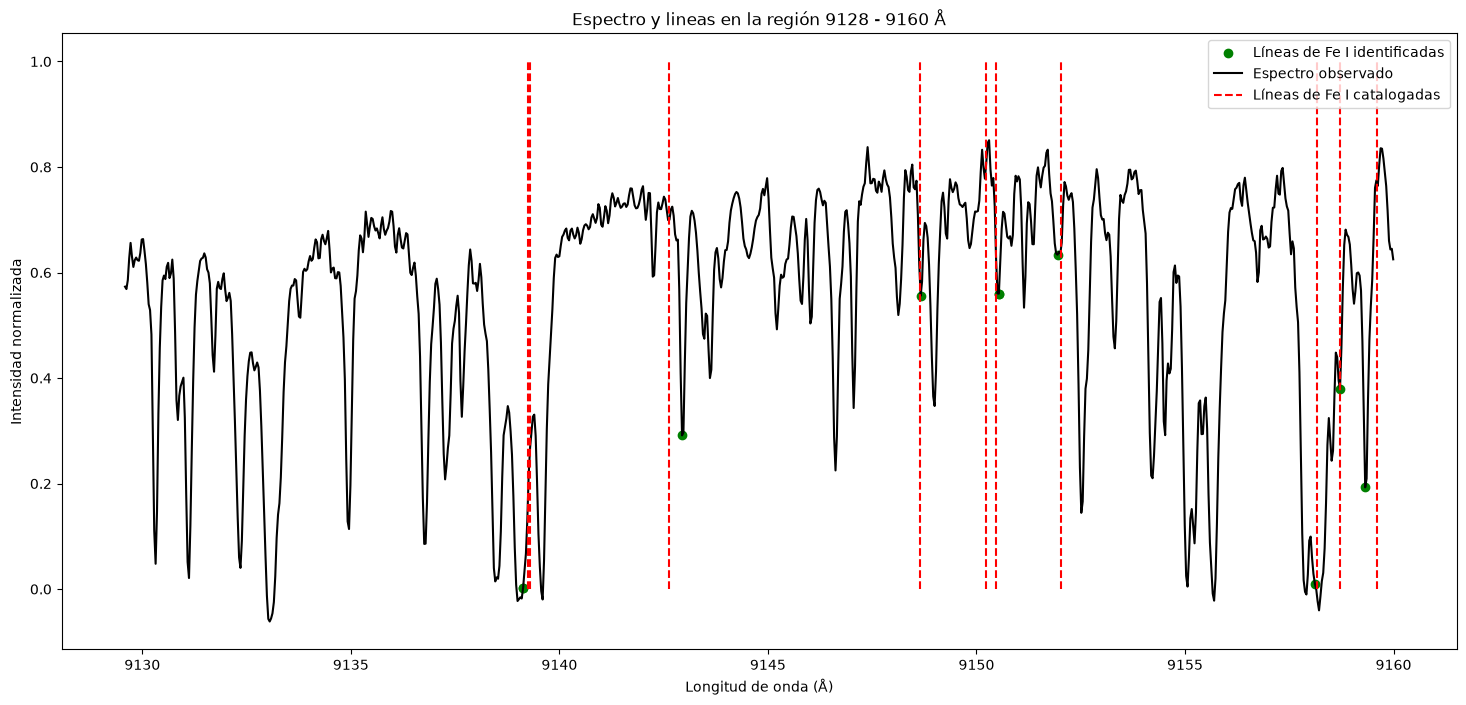

[9130.31886726 9130.85241986 9131.11921954 9131.71957585 9132.35337093
 9132.95388954 9133.05398366 9133.18744589 9133.7880742  9134.95618875
 9136.75900884 9137.2599185  9137.66068576 9138.46232578 9138.52913546
 9138.96342221 9139.13046657 9139.53139795 9139.63163629 9142.23860511
 9142.94073546 9143.6095313  9143.87707703 9144.54600987 9145.21504059
 9145.81725194 9146.01800668 9146.62032379 9147.05537993 9148.1264637
 9148.66209965 9148.99690398 9149.83402201 9150.53731955 9151.14023207
 9151.94423903 9152.51382945 9153.3180778  9154.22302617 9154.52471539
 9155.06110088 9155.22873423 9155.39637373 9155.63107934 9155.73167114
 9156.73771074 9157.84460969 9157.94525014 9158.11298913 9158.21363548
 9158.28073427 9158.51558779 9158.7169004  9159.32089131 9159.99208577]


In [244]:
lambda_min = 9128
lambda_max = 9160

ventana_busqueda = 0.5
identificaciones = []


for linea in fe_lines["lambda"]:
    if any(abs(lambdas_minimos - linea) <= ventana_busqueda):
        identificaciones.append(linea)
        

spectro = spectra.copy()
spectro = spectro[(spectro["lambda"] >= lambda_min) & (spectro["lambda"] <= lambda_max)]
lineas_identificadas = [linea for linea in identificaciones if lambda_min <= linea <= lambda_max]
minimos_region = lambdas_minimos[(lambdas_minimos >= lambda_min) & (lambdas_minimos <= lambda_max)]

intensidades_minimas = [intensidades_minimos[np.argmin(abs(lambdas_minimos - linea))] for linea in lineas_identificadas]
lambdas_minimas = [lambdas_minimos[np.argmin(abs(lambdas_minimos - linea))] for linea in lineas_identificadas]

catalogadas = fe_lines[(fe_lines["lambda"] >= lambda_min) & (fe_lines["lambda"] <= lambda_max)]

identificaciones_region = [linea for linea in identificaciones if lambda_min <= linea <= lambda_max]


plt.figure(figsize=(18,8))
plt.scatter(lambdas_minimas, y=intensidades_minimas, color="green", label="Líneas de Fe I identificadas")
plt.plot(spectro["lambda"], spectro["intensity"], color="black", label="Espectro observado")
plt.xlabel("Longitud de onda (Å)")
plt.ylabel("Intensidad normalizada")
plt.title(f"Espectro y lineas en la región {lambda_min} - {lambda_max} Å")
plt.vlines(catalogadas["lambda"], ymin=0, ymax=1, color="red", linestyle="--", label="Líneas de Fe I catalogadas")
plt.legend()
plt.show()

print(minimos_region)